In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

print("Notebook siap digunakan!")

In [1]:
# from neo4j import GraphDatabase, RoutingControl
# 2
# 3 URI = "neo4j://127.0.0.1:7687"
# 4 AUTH = ("neo4j", "password")

from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "luthfi07052005")

driver = GraphDatabase.driver(URI, auth=AUTH)
# driver.verify_connectivity()

print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


In [ ]:
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", "luthfi07052005")

In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

In [ ]:
def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

In [ ]:
driver.execute_query(
    "MATCH (n) RETURN n",
    database_="movielens")

# SOAL UTS

In [2]:
from neo4j import GraphDatabase

uri      = "neo4j://127.0.0.1:7687"
user     = "neo4j"
password = "luthfi07052005"

driver = GraphDatabase.driver(uri, auth=(user, password))

driver.verify_connectivity()
print("Uji Koneksi Neo4J Telah Berhasil")

Uji Koneksi Neo4J Telah Berhasil


In [ ]:
# Latihan membca data di Neo4J dari PDF
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (n)
        RETURN labels(n) AS label, count(n) AS jumlah
    """)
    for record in hasil:
        print(record["label"], record["jumlah"])

In [100]:
import pandas as pd

df_events = pd.read_csv("Dataset/events.csv")
df_events

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN
...,...,...,...,...,...
2756096,1438398785939,591435,view,261427,NaN
2756097,1438399813142,762376,view,115946,NaN
2756098,1438397820527,1251746,view,78144,NaN
2756099,1438398530703,1184451,view,283392,NaN


In [101]:
df_property1 = pd.read_csv("Dataset/item_properties_part1.csv")
df_property1

,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513
...,...,...,...,...
10999994,1439694000000,86599,categoryid,618
10999995,1435460400000,153032,1066,n1020.000 424566
10999996,1440298800000,421788,888,35975 856003 37346
10999997,1437879600000,159792,400,n552.000 639502 n720.000 424566


In [102]:
df_property2 = pd.read_csv("Dataset/item_properties_part2.csv")
df_property2

,timestamp,itemid,property,value
0,1433041200000,183478,561,769062
1,1439694000000,132256,976,n26.400 1135780
2,1435460400000,420307,921,1149317 1257525
3,1431831600000,403324,917,1204143
4,1435460400000,230701,521,769062
...,...,...,...,...
9275898,1433646000000,236931,929,n12.000
9275899,1440903600000,455746,6,150169 639134
9275900,1439694000000,347565,686,610834
9275901,1433646000000,287231,867,769062


In [103]:
df_category_tree = pd.read_csv("Dataset/category_tree.csv")
df_category_tree

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0
...,...,...
1664,49,1125.0
1665,1112,630.0
1666,1336,745.0
1667,689,207.0


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pathlib import Path
from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm

In [164]:
print("Ukuran file events                : ", df_events.shape)
print("Ukuran file item_properties_part1 : ", df_property1.shape)
print("Ukuran file item_properties_part2 : ", df_property2.shape)
print("Ukuran file category_tree         : ", df_category_tree.shape)

Ukuran file events                :  (2756101, 6)
Ukuran file item_properties_part1 :  (10999999, 4)
Ukuran file item_properties_part2 :  (9275903, 4)
Ukuran file category_tree         :  (1669, 2)


In [105]:
print("EVENTS")
print(df_events.columns.tolist())

print("PROPERTY PART 1")
print(df_property1.columns.tolist())

print("PROPERTY PART 2")
print(df_property2.columns.tolist())

print("CATEGORY TREE")
print(df_category_tree.columns.tolist())

EVENTS
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']
PROPERTY PART 1
['timestamp', 'itemid', 'property', 'value']
PROPERTY PART 2
['timestamp', 'itemid', 'property', 'value']
CATEGORY TREE
['categoryid', 'parentid']


In [106]:
display(df_category_tree.head())
print(df_category_tree.columns.tolist())
display(df_category_tree.isna().sum().to_frame("Jumlah missing"))

,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


['categoryid', 'parentid']


,Jumlah missing
categoryid,0
parentid,25


In [107]:
print("Kolom events:")
display(df_events.isna().sum().to_frame("Jumlah missing"))

print("Jenis event:")
display(df_events["event"].value_counts(dropna=False))

print("Timestamp events:")
print("Minimum:", df_events["timestamp"].min())
print("Maksimum:", df_events["timestamp"].max())

Kolom events:


,Jumlah missing
timestamp,0
visitorid,0
event,0
itemid,0
transactionid,2733644


Jenis event:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

Timestamp events:
Minimum: 1430622004384
Maksimum: 1442545187788


In [108]:
df_events["tanggal"] = pd.to_datetime(
    df_events["timestamp"],
    unit="ms",
    errors="coerce"
)

print("Tanggal paling awal:", df_events["tanggal"].min())
print("Tanggal paling akhir:", df_events["tanggal"].max())

Tanggal paling awal: 2015-05-03 03:00:04.384000
Tanggal paling akhir: 2015-09-18 02:59:47.788000


## 2.1 Wrangling dan EDA

Soal No 1

In [185]:
# Menentukan Timestamp P1 dan P2
df_events["tanggal"] = pd.to_datetime(
    df_events["timestamp"], unit="ms", errors="coerce"
).dt.normalize()

# Periode P1 dan P2
P1_mulai = "2015-05-12"
P1_akhir = "2015-07-01" # Batas akhir, sehingga data terakhir 30 Juni

P2_mulai = "2015-07-01"
P2_akhir  = "2015-07-15" # Batas akhir, sehingga data terakhir 14 Juli

In [186]:
unix_P1_mulai = int(pd.Timestamp(P1_mulai, tz="UTC").timestamp() * 1000)
unix_P1_akhir = int(pd.Timestamp(P1_akhir, tz="UTC").timestamp() * 1000)

unix_P2_mulai = int(pd.Timestamp(P2_mulai, tz="UTC").timestamp() * 1000)
unix_P2_akhir = int(pd.Timestamp(P2_akhir, tz="UTC").timestamp() * 1000)

print("UNIX Timestamp P1 Mulai :", unix_P1_mulai)
print("UNIX Timestamp P1 Akhir :", unix_P1_akhir)
print("UNIX Timestamp P2 Mulai :", unix_P2_mulai)
print("UNIX Timestamp P2 Akhir :", unix_P2_akhir)

UNIX Timestamp P1 Mulai : 1431388800000
UNIX Timestamp P1 Akhir : 1435708800000
UNIX Timestamp P2 Mulai : 1435708800000
UNIX Timestamp P2 Akhir : 1436918400000


Soal No 2

In [ ]:
# Filter pada Timestamp
batas_p1_mulai = pd.Timestamp(P1_mulai)
batas_p1_akhir = pd.Timestamp(P1_akhir)

batas_p2_mulai = pd.Timestamp(P2_mulai)
batas_p2_akhir = pd.Timestamp(P2_akhir)

p1 = df_events[
    (df_events["tanggal"] >= batas_p1_mulai) &
    (df_events["tanggal"] < batas_p1_akhir)
].copy()

p2 = df_events[
    (df_events["tanggal"] >= batas_p2_mulai) &
    (df_events["tanggal"] < batas_p2_akhir)
].copy()

for nama, data in [("P1", p1), ("P2", p2)]:
    print(f"\n--- {nama} ---")
    print("Jumlah event:", len(data))
    print("Tanggal paling awal:", data["tanggal"].min())
    print("Tanggal paling akhir:", data["tanggal"].max())
    print("Jumlah visitorid:", data["visitorid"].nunique())
    print("Jumlah itemid:", data["itemid"].nunique())
    print(
        "Jumlah event transaksi:",
        (data["event"] == "transaction").sum()
    )

print("\nP1 kosong:", p1.empty)
print("P2 kosong:", p2.empty)

p1.head()
p2.head()


--- P1 ---
Jumlah event: 1037409
Tanggal paling awal: 2015-05-12 00:00:00
Tanggal paling akhir: 2015-06-30 00:00:00
Jumlah visitorid: 527427
Jumlah itemid: 152588
Jumlah event transaksi: 8384

--- P2 ---
Jumlah event: 309637
Tanggal paling awal: 2015-07-01 00:00:00
Tanggal paling akhir: 2015-07-14 00:00:00
Jumlah visitorid: 171802
Jumlah itemid: 83507
Jumlah event transaksi: 2473

P1 kosong: False
P2 kosong: False


,timestamp,visitorid,event,itemid,transactionid,tanggal
0,1433221332117,257597,view,355908,NaN,2015-06-02
1,1433224214164,992329,view,248676,NaN,2015-06-02
2,1433221999827,111016,view,318965,NaN,2015-06-02
3,1433221955914,483717,view,253185,NaN,2015-06-02
4,1433221337106,951259,view,367447,NaN,2015-06-02


,timestamp,visitorid,event,itemid,transactionid,tanggal
589558,1435717475012,457980,view,278224,NaN,2015-07-01
589559,1435718665275,554795,view,6605,NaN,2015-07-01
589560,1435720737471,1291838,view,444688,NaN,2015-07-01
589561,1435717706116,567028,view,296749,NaN,2015-07-01
589562,1435721029856,174978,view,99274,NaN,2015-07-01


In [111]:
from pathlib import Path

folder_hasil = Path("Hasil Output")
folder_hasil.mkdir(parents=True, exist_ok=True)

p1.to_csv(folder_hasil / "P1_events.csv", index=False)
p2.to_csv(folder_hasil / "P2_events.csv", index=False)

print("File P1_events.csv dan P2_events.csv berhasil disimpan.")

File P1_events.csv dan P2_events.csv berhasil disimpan.


In [ ]:
# Mengecek node di database neo4j 
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (n)
        RETURN labels(n) AS label, count(n) AS jumlah
        ORDER BY jumlah DESC
    """)
    
    data_node = hasil.data()

display(pd.DataFrame(data_node))

,label,jumlah
0,[Visitor],527427
1,[Item],422791
2,[Person],4


In [113]:
# Mengecek relasi di database neo4j
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relasi, count(r) AS jumlah
        ORDER BY jumlah DESC
    """)
    
    data_relasi = hasil.data()

display(pd.DataFrame(data_relasi))


,jenis_relasi,jumlah
0,VIEWED,1003710
1,ADDED_TO_CART,25187
2,BOUGHT,8384
3,SIMILAR_TO,10
4,KNOWS,3


In [ ]:
# Buat constraint untuk identitas node
with driver.session(database="neo4j") as session:
    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT category_id_unique IF NOT EXISTS
        FOR (c:Category)
        REQUIRE c.categoryId IS UNIQUE
    """)

    session.run("""
        CREATE CONSTRAINT property_id_value_unique IF NOT EXISTS
        FOR (p:ItemProperty)
        REQUIRE (p.propertyId, p.value) IS UNIQUE
    """)

print("Constraint berhasil diperiksa/dibuat.")

In [ ]:
# Pilih kolom yang relevan dan menangani data yang tidak terpakai
kolom_event = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

events_p1 = p1[kolom_event].copy()

events_p1 = events_p1.dropna(subset=["timestamp", "visitorid", "event", "itemid"])

events_p1["timestamp"] = pd.to_numeric(events_p1["timestamp"],errors="coerce")

events_p1["visitorid"] = pd.to_numeric(
    events_p1["visitorid"],
    errors="coerce"
)

events_p1["itemid"] = pd.to_numeric(
    events_p1["itemid"],
    errors="coerce"
)

events_p1 = events_p1.dropna(
    subset=["timestamp", "visitorid", "itemid"]
)

events_p1["transactionid"] = (
    events_p1["transactionid"].fillna("").astype(str)
)

events_p1 = events_p1[
    events_p1["event"].isin(
        ["view", "addtocart", "transaction"]
    )
].copy()

print("Baris siap impor:", len(events_p1))
events_p1.head()

Baris siap impor: 1037409


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,
1,1433224214164,992329,view,248676,
2,1433221999827,111016,view,318965,
3,1433221955914,483717,view,253185,
4,1433221337106,951259,view,367447,


In [ ]:
# Membentuk relasi sesuai jenis event
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: toInteger(row.visitorid)})
    MERGE (i:Item {itemId: toInteger(row.itemid)})

    FOREACH (_ IN CASE
        WHEN row.event = 'view' THEN [1]
        ELSE []
    END |
        MERGE (v)-[:VIEWED {
            timestamp: toInteger(row.timestamp)
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'addtocart' THEN [1]
        ELSE []
    END |
        MERGE (v)-[:ADDED_TO_CART {
            timestamp: toInteger(row.timestamp)
        }]->(i)
    )

    FOREACH (_ IN CASE
        WHEN row.event = 'transaction' THEN [1]
        ELSE []
    END |
        MERGE (v)-[:BOUGHT {
            timestamp: toInteger(row.timestamp),
            transactionId: row.transactionid
        }]->(i)
    )
    """

    tx.run(cypher_query, batch=batch)

In [ ]:
# Impor Data P1 secara Batch
batch_size = 5000
total_baris = len(events_p1)

with driver.session(database="neo4j") as session:
    for awal in range(0, total_baris, batch_size):
        batch = events_p1.iloc[
            awal:awal + batch_size
        ].to_dict("records")

        session.execute_write(import_batch, batch)

        selesai = min(awal + len(batch), total_baris)

        if selesai % 50000 == 0 or selesai == total_baris:
            print(f"Progres impor: {selesai:,} / {total_baris:,}")

print("Impor interaksi P1 selesai.")


In [ ]:
with driver.session(database="neo4j") as session:
    hasil = session.run("""
        MATCH (n)
        WHERE n:Visitor OR n:Item
        RETURN labels(n) AS label, count(n) AS jumlah
        ORDER BY jumlah DESC
    """).data()

display(pd.DataFrame(hasil))


In [7]:
# Menghitung Jumlah Node / Simpul
query_node = """
MATCH (n)
RETURN labels(n) AS label, count(n) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    hasil_node = session.run(query_node).data()

df_node = pd.DataFrame(hasil_node)
df_node


,label,jumlah
0,[Visitor],527427
1,[Item],422791
2,[Person],4


In [165]:
# Jumlah relasi berdasarkan tipe
query_relasi = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    hasil_relasi = session.run(query_relasi).data()

df_relasi = pd.DataFrame(hasil_relasi)
df_relasi

,jenis_relasi,jumlah
0,VIEWED,1003710
1,ADDED_TO_CART,25187
2,BOUGHT,8384
3,SIMILAR_TO,10
4,KNOWS,3


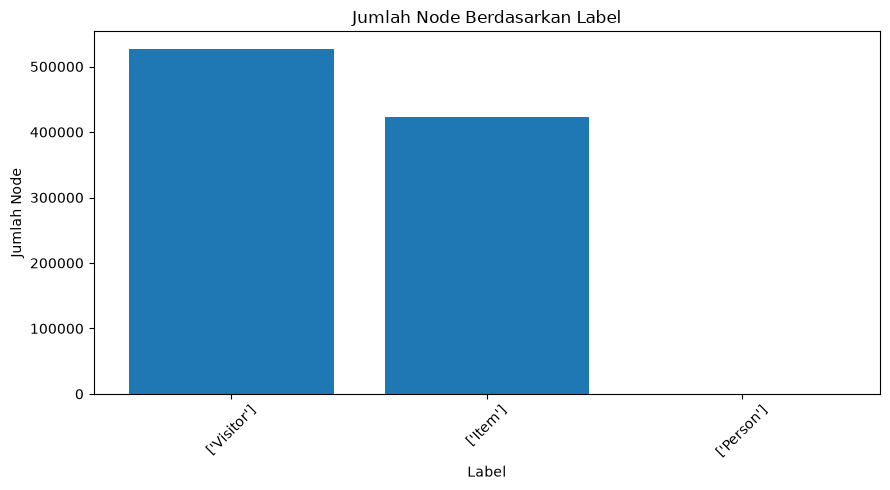

In [9]:
if not df_node.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        df_node["label"].astype(str),
        df_node["jumlah"]
    )
    plt.title("Jumlah Node Berdasarkan Label")
    plt.xlabel("Label")
    plt.ylabel("Jumlah Node")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

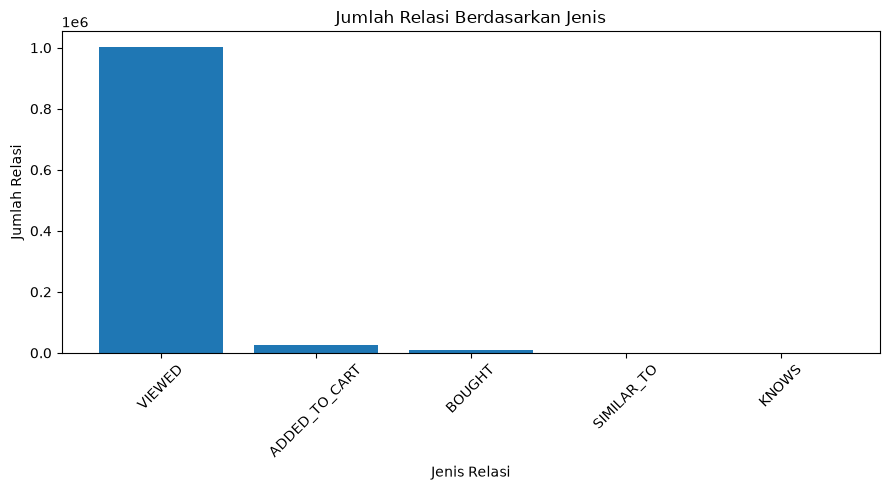

In [10]:
if not df_relasi.empty:
    plt.figure(figsize=(9, 5))
    plt.bar(
        df_relasi["jenis_relasi"],
        df_relasi["jumlah"]
    )
    plt.title("Jumlah Relasi Berdasarkan Jenis")
    plt.xlabel("Jenis Relasi")
    plt.ylabel("Jumlah Relasi")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

Soal no 4 dan 5

In [11]:
# Ambil interaksi P1 dari Neo4j dengan Python
query_interaksi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    v.visitorId AS visitorId,
    i.itemId AS itemId,
    type(r) AS jenis_event
"""

with driver.session(database="neo4j") as session:
    hasil_interaksi = session.run(query_interaksi).data()

interaksi = pd.DataFrame(hasil_interaksi)

print("Ukuran data interaksi:", interaksi.shape)
interaksi.head()

Ukuran data interaksi: (1037281, 3)


,visitorId,itemId,jenis_event
0,257597,355908,VIEWED
1,981382,355908,VIEWED
2,1102250,355908,VIEWED
3,76757,355908,VIEWED
4,979686,355908,VIEWED


In [12]:
# Membentuk Matriks VSM USer-Item, VSM terhadap simpul sebagai User dan VSM terhadap simpul sebagai Item
interaksi = interaksi.dropna(
    subset=["visitorId", "itemId"]
).copy()

interaksi["visitorId"] = interaksi["visitorId"].astype(int)
interaksi["itemId"] = interaksi["itemId"].astype(int)

# Setiap pasangan user-item dihitung satu kali untuk VSM biner
interaksi_unik = interaksi.drop_duplicates(subset=["visitorId", "itemId"])

user_ids = np.sort(interaksi_unik["visitorId"].unique())
item_ids = np.sort(interaksi_unik["itemId"].unique())

index_user = {user_id: idx for idx, user_id in enumerate(user_ids)}

index_item = {item_id: idx for idx, item_id in enumerate(item_ids)}

baris = interaksi_unik["visitorId"].map(index_user).to_numpy()
kolom = interaksi_unik["itemId"].map(index_item).to_numpy()

X_user_item = csr_matrix(
    (np.ones(len(interaksi_unik), dtype=np.float32),
        (baris, kolom)),
    shape=(len(user_ids), len(item_ids))
)

print("Jumlah user:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Shape VSM User–Item:", X_user_item.shape)
print("Jumlah interaksi unik:", X_user_item.nnz)

Jumlah user: 527427
Jumlah item: 152588
Shape VSM User–Item: (527427, 152588)
Jumlah interaksi unik: 800556


In [13]:
# Proyeksi user: baris pengguna, kolom item
X_user = normalize(X_user_item, norm="l2", axis=1)

# Proyeksi item: baris item, kolom pengguna
X_item = normalize(X_user_item.T.tocsr(), norm="l2", axis=1)

print("Shape VSM User:", X_user.shape)
print("Shape VSM Item:", X_item.shape)

Shape VSM User: (527427, 152588)
Shape VSM Item: (152588, 527427)


In [14]:
# Menganalisis Karakteristik VSM
def ringkasan_vsm(nama, matriks):
    total_elemen = matriks.shape[0] * matriks.shape[1]
    kepadatan = (matriks.nnz / total_elemen if total_elemen > 0 else 0)

    return {
        "Nama": nama,
        "Shape": matriks.shape,
        "Jumlah baris": matriks.shape[0],
        "Jumlah kolom": matriks.shape[1],
        "Elemen nonzero": matriks.nnz,
        "Kepadatan": kepadatan
    }

df_vsm = pd.DataFrame([
    ringkasan_vsm("User–Item", X_user_item),
    ringkasan_vsm("User Projection", X_user),
    ringkasan_vsm("Item Projection", X_item)
])

df_vsm

,Nama,Shape,Jumlah baris,Jumlah kolom,Elemen nonzero,Kepadatan
0,User–Item,"(527427, 152588)",527427,152588,800556,0.00001
1,User Projection,"(527427, 152588)",527427,152588,800556,0.00001
2,Item Projection,"(152588, 527427)",152588,527427,800556,0.00001


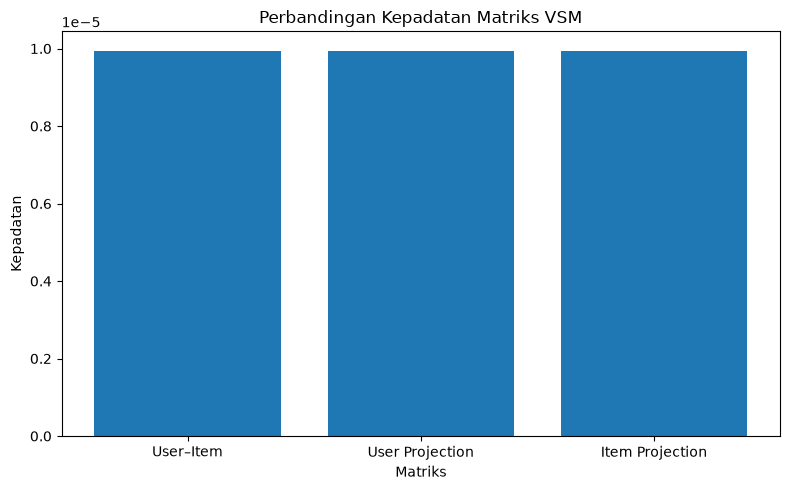

In [15]:
# Perbandingan Kepadatan Matriks
plt.figure(figsize=(8, 5))

plt.bar(df_vsm["Nama"], df_vsm["Kepadatan"])

plt.title("Perbandingan Kepadatan Matriks VSM")
plt.xlabel("Matriks")
plt.ylabel("Kepadatan")
plt.tight_layout()
plt.show()

Soal no 6

Graf bipartit: 104 node, 100 edge
Proyeksi User: 99 node, 2111 edge
Proyeksi Item: 5 node, 1 edge


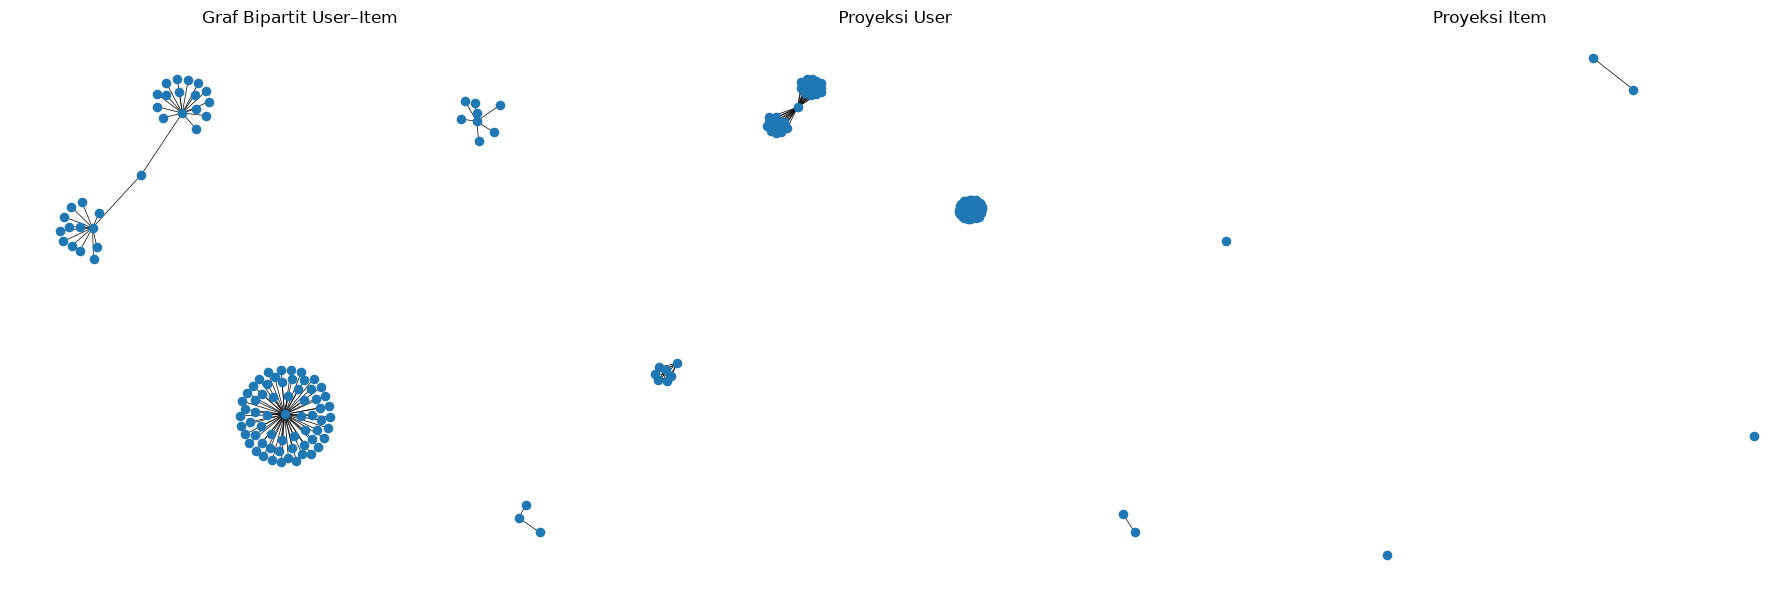

In [16]:
# Plot NetworkX untuk User dan Item
jumlah_sampel = min(100, len(interaksi_unik))

sampel = interaksi_unik.head(jumlah_sampel)

G_bipartit = nx.Graph()

users_sample = set()
items_sample = set()

for row in sampel.itertuples(index=False):
    u = f"U{row.visitorId}"
    i = f"I{row.itemId}"

    users_sample.add(u)
    items_sample.add(i)

    G_bipartit.add_node(u,tipe="User")
    G_bipartit.add_node(i,tipe="Item")
    G_bipartit.add_edge(u, i)

# Proyeksi graf pengguna yang memiliki item bersama
G_user_projection = nx.bipartite.projected_graph(G_bipartit, users_sample)

# Proyeksi graf item yang memiliki pengguna bersama
G_item_projection = nx.bipartite.projected_graph(G_bipartit, items_sample)

print("Graf bipartit:", 
      G_bipartit.number_of_nodes(), "node,",
      G_bipartit.number_of_edges(), "edge")

print("Proyeksi User:",
      G_user_projection.number_of_nodes(), "node,",
      G_user_projection.number_of_edges(), "edge")

print("Proyeksi Item:",
      G_item_projection.number_of_nodes(), "node,",
      G_item_projection.number_of_edges(), "edge")


fig, axes = plt.subplots(1, 3, figsize=(18, 6))

daftar_graf = [
    (G_bipartit, "Graf Bipartit User–Item"),
    (G_user_projection, "Proyeksi User"),
    (G_item_projection, "Proyeksi Item")
]

for ax, (graf, judul) in zip(axes, daftar_graf):
    pos = nx.spring_layout(graf, seed=42)

    nx.draw_networkx(graf, pos, ax=ax, with_labels=False, node_size=35, width=0.5)

    ax.set_title(judul)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# Membandingkan karakteristik proyeksi User dan Item
def karakteristik_graf(nama, graf):
    return {
        "Graf Proyeksi": nama,
        "Jumlah node": graf.number_of_nodes(),
        "Jumlah edge": graf.number_of_edges(),
        "Density": nx.density(graf) if graf.number_of_nodes() > 1 else 0,
        "Jumlah connected components": nx.number_connected_components(graf)
    }

df_proyeksi = pd.DataFrame([
    karakteristik_graf("Bipartit", G_bipartit),
    karakteristik_graf("Proyeksi User", G_user_projection),
    karakteristik_graf("Proyeksi Item", G_item_projection)
])

df_proyeksi

,Graf Proyeksi,Jumlah node,Jumlah edge,Density,Jumlah connected components
0,Bipartit,104,100,0.018671,4
1,Proyeksi User,99,2111,0.435168,4
2,Proyeksi Item,5,1,0.100000,4


In [18]:
import time

waktu_proyeksi = []

awal = time.perf_counter()

G_user_uji = nx.bipartite.projected_graph(
    G_bipartit, users_sample
)

waktu_user = time.perf_counter() - awal

awal = time.perf_counter()

G_item_uji = nx.bipartite.projected_graph(
    G_bipartit, items_sample
)

waktu_item = time.perf_counter() - awal

waktu_proyeksi = pd.DataFrame([
    {
        "Proyeksi": "User",
        "Waktu (detik)": waktu_user
    },
    {
        "Proyeksi": "Item",
        "Waktu (detik)": waktu_item
    }
])

display(waktu_proyeksi)

,Proyeksi,Waktu (detik)
0,User,0.006136
1,Item,0.000154


Soal no 7

In [96]:
# Menentukan record acuan secara reproducible
rng = np.random.default_rng(42)

user_tersedia = list(G_user_projection.nodes())
user_target = rng.choice(user_tersedia)

print("Record acuan:", user_target)

Record acuan: U111016


In [ ]:
# Menghitung cosine similarity pada graf proyeksi
daftar_user = list(G_user_projection.nodes())

A_user = nx.to_scipy_sparse_array(
    G_user_projection,
    nodelist=daftar_user,
    dtype=np.float32,
    format="csr")

A_user_norm = normalize(A_user, norm="l2", axis=1)

# Cari posisi record acuan
idx_target = daftar_user.index(user_target)

# Hitung similarity record acuan terhadap seluruh user
similarity_user = cosine_similarity(
    A_user_norm[idx_target:idx_target + 1],
    A_user_norm
).ravel()

hasil_similarity = pd.DataFrame({
    "user_mirip": daftar_user,
    "similarity": similarity_user})

# Menghapus record acuan dari hasil
hasil_similarity = hasil_similarity[
    hasil_similarity["user_mirip"] != user_target].copy()


# Mengambil similarity positif saja
hasil_similarity = hasil_similarity[
    hasil_similarity["similarity"] > 0].copy()

hasil_similarity = hasil_similarity.sort_values("similarity", ascending=False)

top5_similarity = hasil_similarity.head(5).copy()
top5_similarity

,user_mirip,similarity
29,U595101,0.833333
32,U1181577,0.833333
62,U499741,0.833333
66,U1382035,0.833333
87,U138467,0.833333


In [ ]:
# Menyimpan Hasil Similarity
def simpan_similarity(tx, visitor_a, visitor_b, nilai):
    query = """
    MATCH (a:Visitor {visitorId: $visitor_a})
    MATCH (b:Visitor {visitorId: $visitor_b})
    MERGE (a)-[r:SIMILAR_TO]->(b)
    SET r.similarity = $nilai
    """
    tx.run(
        query,
        visitor_a=int(visitor_a),
        visitor_b=int(visitor_b),
        nilai=float(nilai)
    )

id_target = int(str(user_target)[1:])

with driver.session(database="neo4j") as session:
    for row in top5_similarity.itertuples(index=False):
        id_mirip = int(str(row.user_mirip)[1:])

        session.execute_write(
            simpan_similarity,
            id_target,
            id_mirip,
            float(row.similarity))

print("Similarity berhasil disimpan ke Neo4j.")

Similarity berhasil disimpan ke Neo4j.


In [22]:
# Top 5 Similarity
query_top_similarity = """
MATCH (a:Visitor {visitorId: $user_target})-[r:SIMILAR_TO]->(b:Visitor)
RETURN
    a.visitorId AS user_target,
    b.visitorId AS user_mirip,
    r.similarity AS similarity
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    hasil_top_similarity = session.run(
        query_top_similarity,
        user_target=int(id_target)
    ).data()

print("Jumlah Hasil Top", len(hasil_top_similarity), "Similarity")

if hasil_top_similarity:
    display(pd.DataFrame(hasil_top_similarity))
else:
    print("Belum ada relasi SIMILAR_TO untuk ID target tersebut.")

Jumlah Hasil Top 5 Similarity


,user_target,user_mirip,similarity
0,111016,1181577,0.833333
1,111016,138467,0.833333
2,111016,595101,0.833333
3,111016,1382035,0.833333
4,111016,499741,0.833333


Soal no 8

In [ ]:
id_target = int(str(user_target)[1:])

query_sebelum = """
MATCH (u:Visitor {visitorId: $user_target})
OPTIONAL MATCH (u)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
RETURN
    u.visitorId AS userId,
    i.itemId AS itemId,
    type(r) AS jenis_relasi
LIMIT 100
"""

with driver.session(database="neo4j") as session:
    data_sebelum = session.run(
        query_sebelum,
        user_target=id_target
    ).data()

display(pd.DataFrame(data_sebelum))

,userId,itemId,jenis_relasi
0,111016,318965,VIEWED
1,111016,318965,VIEWED


In [25]:
query_sesudah = """
MATCH (u:Visitor {visitorId: $user_target})
OPTIONAL MATCH (u)-[r]->(i:Item)
WHERE type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']
WITH u, collect({
    itemId: i.itemId,
    jenis_relasi: type(r)
}) AS relasi_item

OPTIONAL MATCH (u)-[s:SIMILAR_TO]->(v:Visitor)
RETURN
    u.visitorId AS userId,
    relasi_item,
    collect({
        user_mirip: v.visitorId,
        similarity: s.similarity
    }) AS relasi_similarity
"""

with driver.session(database="neo4j") as session:
    data_sesudah = session.run(
        query_sesudah,
        user_target=id_target
    ).data()

display(pd.DataFrame(data_sesudah))

,userId,relasi_item,relasi_similarity
0,111016,"[{'itemId': 318965, 'jenis_relasi': 'VIEWED'},...","[{'similarity': 0.8333333730697632, 'user_miri..."


In [ ]:
# Graf sebelum: hanya relasi interaksi dengan item
G_sebelum = nx.Graph()
G_sebelum.add_node(f"U{id_target}", tipe="User")

for row in data_sebelum:
    if row["itemId"] is not None:
        G_sebelum.add_edge(
            f"U{row['userId']}",
            f"I{row['itemId']}",
            jenis=row["jenis_relasi"]
        )

# Graf sesudah: mulai dari graf sebelum
G_sesudah = G_sebelum.copy()

for data in data_sesudah:
    for relasi in data["relasi_similarity"]:
        if relasi["user_mirip"] is not None:
            G_sesudah.add_edge(
                f"U{id_target}",
                f"U{relasi['user_mirip']}",
                jenis="SIMILAR_TO",
                similarity=relasi["similarity"]
            )

print("Sebelum:",
      G_sebelum.number_of_nodes(), "node,",
      G_sebelum.number_of_edges(), "edge")

print("Sesudah:",
      G_sesudah.number_of_nodes(), "node,",
      G_sesudah.number_of_edges(), "edge")

Sebelum: 2 node, 1 edge
Sesudah: 7 node, 6 edge


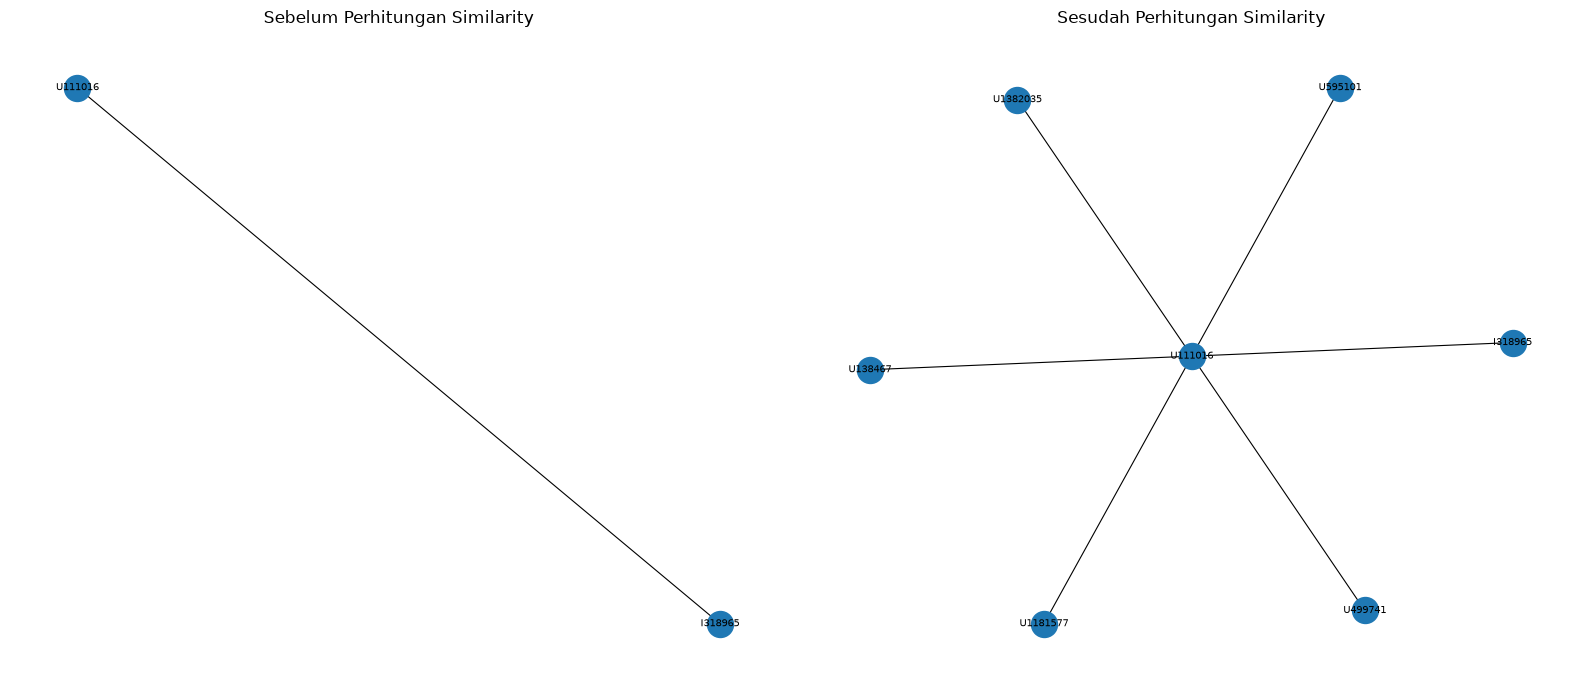

In [ ]:
# Graf sebelum dan sesudah
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

daftar_graf = [
    (G_sebelum, "Sebelum Perhitungan Similarity"),
    (G_sesudah, "Sesudah Perhitungan Similarity")
]

for ax, (graf, judul) in zip(axes, daftar_graf):
    pos = nx.spring_layout(graf, seed=42)

    nx.draw_networkx(
        graf,
        pos,
        ax=ax,
        with_labels=True,
        font_size=7,
        node_size=350,
        width=0.8
    )

    ax.set_title(judul)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.2 Analytics

Soal no 1

In [161]:
events_p1 = pd.read_csv("Hasil Output/P1_events.csv")

print(events_p1.head())
print("\n", events_p1.columns)

       timestamp  visitorid event  itemid  transactionid     tanggal
0  1433221332117     257597  view  355908            NaN  2015-06-02
1  1433224214164     992329  view  248676            NaN  2015-06-02
2  1433221999827     111016  view  318965            NaN  2015-06-02
3  1433221955914     483717  view  253185            NaN  2015-06-02
4  1433221337106     951259  view  367447            NaN  2015-06-02

 Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid',
       'tanggal'],
      dtype='str')


In [173]:
# Menyiapkan data interaksi P1
events_p1_knn = events_p1.copy()

events_p1_knn["visitorid"] = pd.to_numeric(events_p1_knn["visitorid"],errors="coerce")
events_p1_knn["itemid"] = pd.to_numeric(events_p1_knn["itemid"],errors="coerce")

events_p1_knn = events_p1_knn.dropna(subset=["visitorid", "itemid"]).copy()

events_p1_knn["visitorid"] = (events_p1_knn["visitorid"].astype(int))

events_p1_knn["itemid"] = (events_p1_knn["itemid"].astype(int))

user_target_id = int(str(user_target)[1:])

print("User target:", user_target)
print("ID numerik user target:", user_target_id)

item_dikenal_target = set(
    events_p1_knn.loc[
        events_p1_knn["visitorid"] == user_target_id,
        "itemid"].unique())

print("Jumlah item yang sudah dikenal target:",len(item_dikenal_target))

User target: U899857
ID numerik user target: 899857
Jumlah item yang sudah dikenal target: 75


In [175]:
# Memilih 5 tetangga dan mengumpulkan kandidat item
tetangga = top5_similarity.head(5).copy()

# Mengubah ID "U12345" menjadi angka 12345
tetangga["visitorid"] = tetangga["user_mirip"].apply(
    lambda x: int(str(x)[1:]))

print("User target :", user_target)
print("Jumlah tetangga yang ditemukan:", len(tetangga))

tetangga

User target : U899857
Jumlah tetangga yang ditemukan: 5


,user_mirip,similarity,visitorid
0,U1404133,0.983606,1404133
2,U819547,0.983606,819547
30,U1370334,0.983606,1370334
3,U439857,0.983606,439857
4,U1394288,0.983606,1394288


In [177]:
# Menghitung skor dan menampilkan 3 rekomendasi
bobot_tetangga = {
    int(row.visitorid): float(row.similarity)
    for row in tetangga.itertuples(index=False)}

interaksi_tetangga = events_p1_knn[
    events_p1_knn["visitorid"].isin(
        bobot_tetangga.keys())].copy()

interaksi_tetangga["bobot"] = (
    interaksi_tetangga["visitorid"].map(
        bobot_tetangga))

skor_item = (
    interaksi_tetangga
    .groupby("itemid")["bobot"]
    .sum()
    .reset_index(name="skor_rekomendasi"))

skor_item = skor_item[
    ~skor_item["itemid"].isin(item_dikenal_target)].copy()

skor_item = skor_item.sort_values("skor_rekomendasi",ascending=False)

rekomendasi_top5 = skor_item.head(5).copy()

print("5 rekomendasi teratas")
display(rekomendasi_top5)

rekomendasi_top3 = rekomendasi_top5.head(3).copy()

print("\nUser target:", user_target)
print("\n3 Item yang Direkomendasikan untuk k = 5")
rekomendasi_top3

5 rekomendasi teratas


,itemid,skor_rekomendasi
20,265760,11.803273
24,281480,6.885243
42,443344,4.918031
15,158575,3.934424
23,278208,3.934424



User target: U899857

3 Item yang Direkomendasikan untuk k = 5


,itemid,skor_rekomendasi
20,265760,11.803273
24,281480,6.885243
42,443344,4.918031


Soal no 2

In [160]:
events_p2 = pd.read_csv("Hasil Output/P2_events.csv")

print(events_p2.head())
print("\n", events_p2.columns)

       timestamp  visitorid event  itemid  transactionid     tanggal
0  1435717475012     457980  view  278224            NaN  2015-07-01
1  1435718665275     554795  view    6605            NaN  2015-07-01
2  1435720737471    1291838  view  444688            NaN  2015-07-01
3  1435717706116     567028  view  296749            NaN  2015-07-01
4  1435721029856     174978  view   99274            NaN  2015-07-01

 Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid',
       'tanggal'],
      dtype='str')


In [ ]:
# Evaluasi rekomendasi dengan P2
p2_eval = events_p2.copy()

p2_eval["visitorid"] = pd.to_numeric(p2_eval["visitorid"], errors="coerce")
p2_eval["itemid"] = pd.to_numeric(p2_eval["itemid"], errors="coerce")

p2_eval = p2_eval.dropna(subset=["visitorid", "itemid"]).copy()

p2_eval["visitorid"] = p2_eval["visitorid"].astype(int)
p2_eval["itemid"] = p2_eval["itemid"].astype(int)

# Samakan format ID target menjadi numerik
id_target = int(str(user_target).replace("U", ""))

# Ambil item yang ditransaksikan target pada P2
item_relevan = set(
    p2_eval.loc[
        (p2_eval["visitorid"] == id_target) &
        (p2_eval["event"].astype(str).str.lower() == "transaction"),
        "itemid"
    ].unique())

print("User target:", user_target)
print("ID target numerik:", id_target)
print("Jumlah item relevan pada P2:", len(item_relevan))
print("Item relevan:", item_relevan)

User target: U899857
ID target numerik: 899857
Jumlah item relevan pada P2: 9
Item relevan: {np.int64(251204), np.int64(213255), np.int64(335276), np.int64(232172), np.int64(124559), np.int64(349047), np.int64(42997), np.int64(83639), np.int64(34875)}


In [179]:
# Menghitung Nilai Hit@5 dan NDCG@5
daftar_rekomendasi = (rekomendasi_top5["itemid"].astype(int).tolist())

if len(item_relevan) == 0:
    hit_at_5 = np.nan
    ndcg_at_5 = np.nan

    print(
        "Evaluasi tidak dapat dinilai: "
        "user target tidak memiliki transaksi relevan di P2."
    )
else:
    relevansi = [
        1 if item in item_relevan else 0
        for item in daftar_rekomendasi[:5]]

    hit_at_5 = int(any(relevansi))

    dcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(relevansi, start=1))

    jumlah_relevan_ideal = min(len(item_relevan), 5)

    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, jumlah_relevan_ideal + 1))

    ndcg_at_5 = dcg / idcg if idcg > 0 else np.nan

print("Hasil Hit@5:", hit_at_5)
print("Hasil NDCG@5:", ndcg_at_5)

Hasil Hit@5: 0
Hasil NDCG@5: 0.0


In [181]:
folder_hasil.mkdir(parents=True, exist_ok=True)

top5_similarity.to_csv(folder_hasil / "top5_similarity.csv", index=False)

rekomendasi_top5.to_csv(folder_hasil / "rekomendasi_top5.csv", index=False)

hasil_evaluasi = pd.DataFrame([{
    "user_target": user_target,
    "jumlah_item_relevan_P2": len(item_relevan),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

hasil_evaluasi.to_csv(folder_hasil / "hasil_evaluasi.csv", index=False)

display(hasil_evaluasi)
print("Hasil analisis tersimpan di folder hasil.")

,user_target,jumlah_item_relevan_P2,Hit@5,NDCG@5
0,U899857,9,0,0.0


Hasil analisis tersimpan di folder hasil.


In [ ]:
# Tutup Koneksi Neo4j
driver.close()

print("Koneksi Neo4j ditutup.")